In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_absolute_error, r2_score

from sklearn.ensemble import RandomForestRegressor

In [3]:
df = pd.read_csv(r'C:\Users\keert\OneDrive\Documents\healthcare analytics for doctor visit\1776250375-P2-Healthcare Analytics for Doctor Visits.csv')

df.head()

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


In [4]:
df.shape
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   object 
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   object 
 9   freepoor    5190 non-null   object 
 10  freerepat   5190 non-null   object 
 11  nchronic    5190 non-null   object 
 12  lchronic    5190 non-null   object 
dtypes: float64(2), int64(5), object(6)
memory usage: 527.2+ KB


,Unnamed: 0,visits,age,income,illness,reduced,health
count,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000
mean,2595.500000,0.301734,0.406385,0.583160,1.431985,0.861850,1.217534
std,1498.368279,0.798134,0.204782,0.368907,1.384152,2.887628,2.124266
min,1.000000,0.000000,0.190000,0.000000,0.000000,0.000000,0.000000
25%,1298.250000,0.000000,0.220000,0.250000,0.000000,0.000000,0.000000
50%,2595.500000,0.000000,0.320000,0.550000,1.000000,0.000000,0.000000
75%,3892.750000,0.000000,0.620000,0.900000,2.000000,0.000000,2.000000
max,5190.000000,9.000000,0.720000,1.500000,5.000000,14.000000,12.000000


In [5]:
df.isnull().sum()

Unnamed: 0    0
visits        0
gender        0
age           0
income        0
illness       0
reduced       0
health        0
private       0
freepoor      0
freerepat     0
nchronic      0
lchronic      0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [9]:
print(df['visits'].describe())

count    5190.000000
mean        0.301734
std         0.798134
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         9.000000
Name: visits, dtype: float64


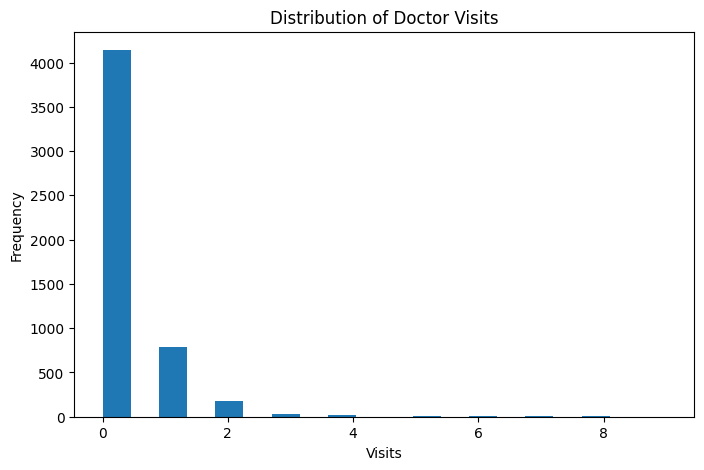

In [10]:
plt.figure(figsize=(8,5))
plt.hist(df['visits'], bins=20)
plt.title('Distribution of Doctor Visits')
plt.xlabel('Visits')
plt.ylabel('Frequency')
plt.show()

In [11]:
print(df['gender'].value_counts())

gender
female    2702
male      2488
Name: count, dtype: int64


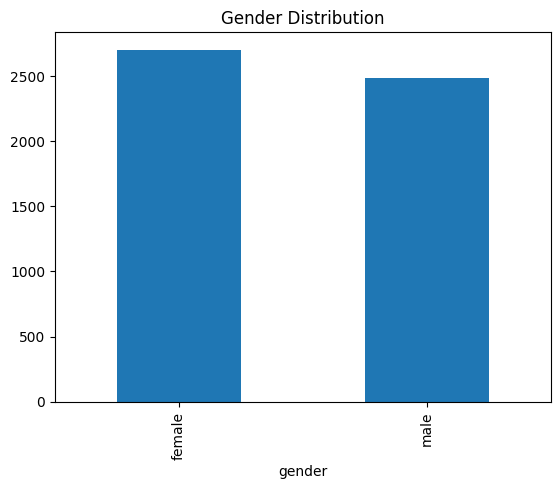

In [12]:
df['gender'].value_counts().plot(kind='bar')
plt.title('Gender Distribution')
plt.show()

In [13]:
df.groupby('gender')['visits'].mean()

gender
female    0.361954
male      0.236334
Name: visits, dtype: float64

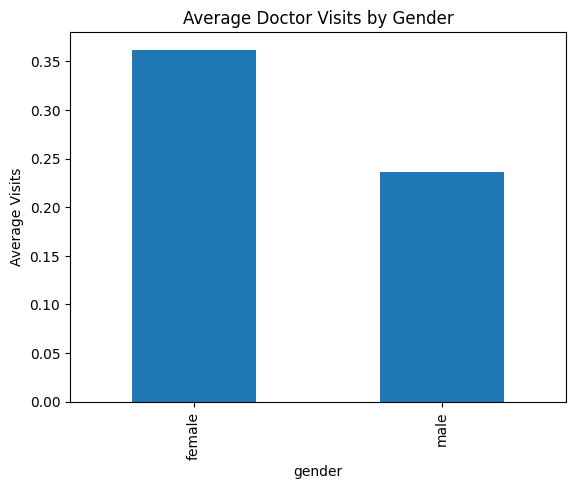

In [14]:
df.groupby('gender')['visits'].mean().plot(kind='bar')
plt.title('Average Doctor Visits by Gender')
plt.ylabel('Average Visits')
plt.show()

In [15]:
print(df['age'].describe())

count    5190.000000
mean        0.406385
std         0.204782
min         0.190000
25%         0.220000
50%         0.320000
75%         0.620000
max         0.720000
Name: age, dtype: float64


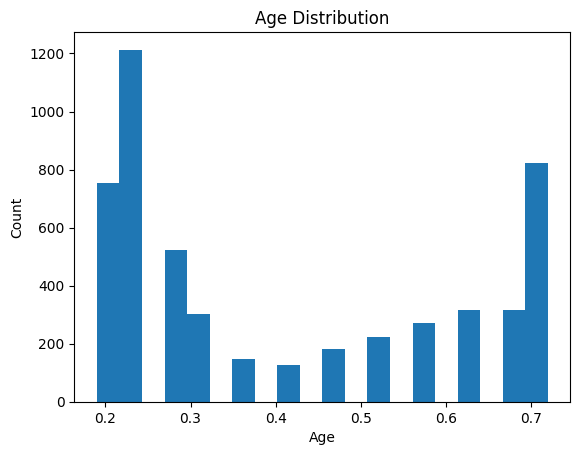

In [16]:
plt.hist(df['age'], bins=20)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

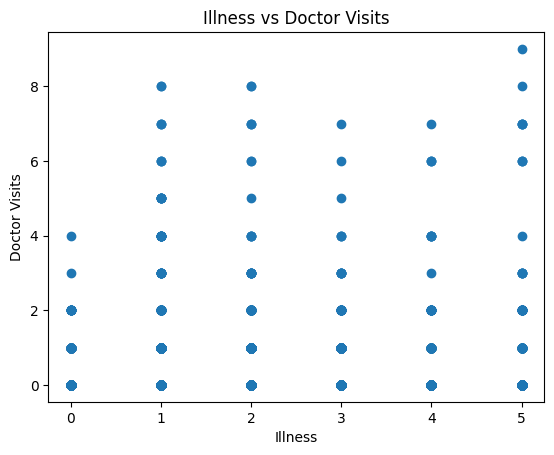

In [17]:
plt.scatter(df['illness'], df['visits'])
plt.xlabel('Illness')
plt.ylabel('Doctor Visits')
plt.title('Illness vs Doctor Visits')
plt.show()

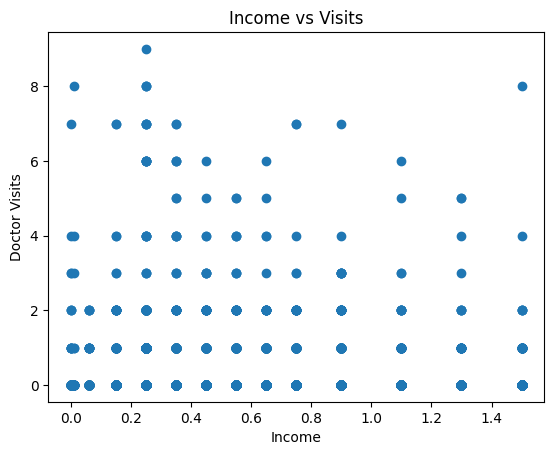

In [18]:
plt.scatter(df['income'], df['visits'])
plt.xlabel('Income')
plt.ylabel('Doctor Visits')
plt.title('Income vs Visits')
plt.show()

In [19]:
df.groupby('nchronic')['visits'].mean()

nchronic
no     0.272111
yes    0.345602
Name: visits, dtype: float64

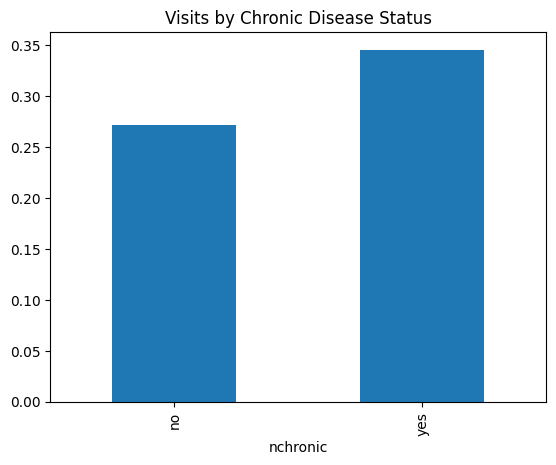

In [20]:
df.groupby('nchronic')['visits'].mean().plot(kind='bar')
plt.title('Visits by Chronic Disease Status')
plt.show()

In [21]:
df.groupby('private')['visits'].mean()

private
no     0.307400
yes    0.294604
Name: visits, dtype: float64

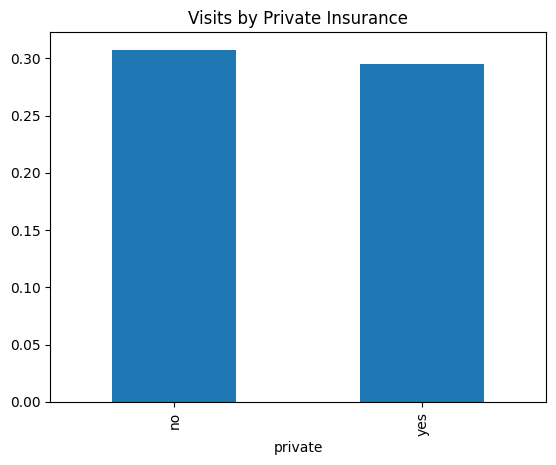

In [22]:
df.groupby('private')['visits'].mean().plot(kind='bar')
plt.title('Visits by Private Insurance')
plt.show()

In [23]:
binary_cols = ['private','freepoor','freerepat','nchronic','lchronic']

for col in binary_cols:
    df[col] = df[col].map({'yes':1,'no':0})

In [24]:
corr = df.corr(numeric_only=True)

corr['visits'].sort_values(ascending=False)

visits        1.000000
reduced       0.418954
illness       0.223552
health        0.193272
lchronic      0.137267
age           0.124537
freerepat     0.106543
nchronic      0.045171
private      -0.007964
freepoor     -0.038163
income       -0.076840
Unnamed: 0   -0.521645
Name: visits, dtype: float64

In [25]:
df['gender'] = df['gender'].map({'male':1,'female':0})

In [26]:
df.head()

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,0,0.19,0.55,1,4,1,1,0,0,0,0
1,2,1,0,0.19,0.45,1,2,1,1,0,0,0,0
2,3,1,1,0.19,0.90,3,0,0,0,0,0,0,0
3,4,1,1,0.19,0.15,1,0,0,0,0,0,0,0
4,5,1,1,0.19,0.45,2,5,1,0,0,0,1,0


In [27]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

In [28]:
X = df.drop('visits', axis=1)
y = df['visits']

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [30]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [31]:
pred = model.predict(X_test)

In [32]:
print("MAE:", mean_absolute_error(y_test, pred))
print("R2:", r2_score(y_test, pred))

MAE: 0.1798169556840077
R2: 0.5116509845166533


In [33]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance)

       Feature  Importance
0   Unnamed: 0    0.693601
5      reduced    0.105865
3       income    0.047788
6       health    0.044140
4      illness    0.038675
2          age    0.020128
7      private    0.013625
1       gender    0.009728
11    lchronic    0.007928
10    nchronic    0.007247
8     freepoor    0.006138
9    freerepat    0.005137


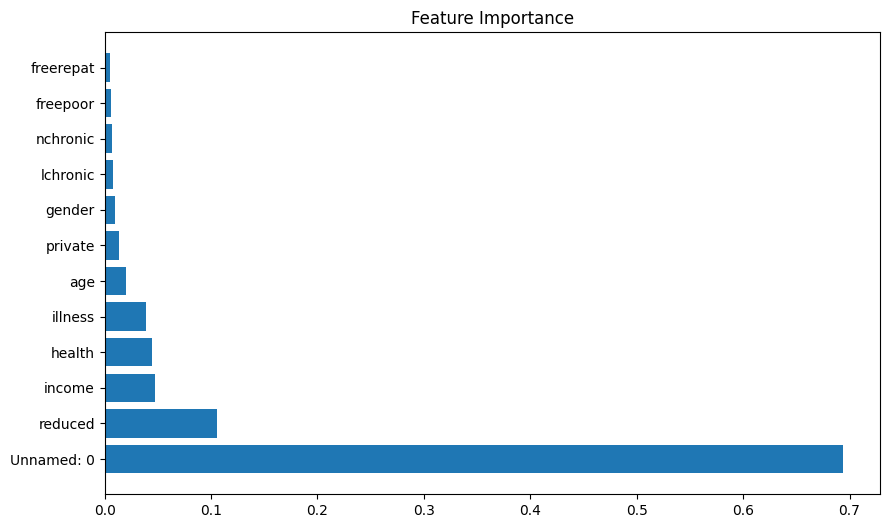

In [34]:
plt.figure(figsize=(10,6))
plt.barh(
    importance['Feature'],
    importance['Importance']
)
plt.title('Feature Importance')
plt.show()